# EDA датасетов Авито

Исследование всех наборов: микрокатегории, длины описаний, отрицания,
языковые ошибки, дубликаты и пересечения выборок.

**Графики и таблицы уже сохранены в выходах ячеек.** Для просмотра запускать
код не требуется. Откройте файл в Jupyter Notebook, JupyterLab или VS Code.

Для пересчёта выберите Python-ядро с зависимостями из
`datasets/requirements-notebook.txt` и выполните **Run All / Restart & Run All**.
Для повторного запуска нужен репозиторий с папкой `datasets/`.
Таблицы, графики и численные выводы рассчитываются заново из исходных файлов.

## 1. Подготовка и загрузка

Используем функции анализа из `datasets/eda.py`. Все 14 JSONL/Parquet
читаются полностью. Файлы данных не изменяются. Для Parquet названия категорий
переводятся в mcId; источник 101 принят по описанию данных организаторов.

In [1]:
from pathlib import Path
from collections import Counter
import hashlib
import importlib.util
import json
import tempfile
from IPython.display import display, HTML, Image, Markdown

# Работает при запуске из корня проекта, datasets/ или datasets/eda/.
project_root = next(
    (p for p in (Path.cwd(), *Path.cwd().parents)
     if (p / "datasets" / "eda.py").is_file()), None
)
if project_root is None:
    raise FileNotFoundError("Откройте notebook внутри репозитория с datasets/eda.py")
spec = importlib.util.spec_from_file_location("avito_eda", project_root / "datasets" / "eda.py")
eda = importlib.util.module_from_spec(spec)
spec.loader.exec_module(eda)

def table(headers, rows):
    report = eda.Report()
    report.table(headers, rows)
    display(HTML(report.html[0]))

data, inventory = eda.load()
stats = {name: eda.summarize(rows) for name, rows in data.items()}
overlap = eda.intersections(data)
public_train = stats[eda.PUBLIC_TRAIN]
public_test = stats[eda.PUBLIC_TEST]
v2_train = stats[eda.V2 + "train.jsonl"]
display(Markdown(
    f"**Файлов:** {len(data)} · **Строк:** {sum(len(rows) for rows in data.values()):,} · "
    f"**Уникальных описаний:** {overlap['unique_texts_all_files']:,}"
))

**Файлов:** 14 · **Строк:** 27,508 · **Уникальных описаний:** 20,341

In [2]:
table(
    ["Файл относительно datasets/", "Строк", "Уникальных текстов", "Повторов сверх первого", "Пустых ответов, %"],
    [[name, s["rows"], s["unique_texts"], s["duplicate_extra_rows"],
      round(100 * s["empty_targets"] / s["rows"], 1)] for name, s in stats.items()]
)

Файл относительно datasets/,Строк,Уникальных текстов,Повторов сверх первого,"Пустых ответов, %"
distillate_dataset/hard_ads_500.jsonl,500,500,0,28.0
distillate_dataset/hard_edits_500.jsonl,500,489,11,34.0
hard_dataset/challenge.jsonl,40,40,0,15.0
hard_dataset/test.jsonl,240,240,0,2.1
hard_dataset/train.jsonl,1320,1320,0,12.1
hard_dataset/v2/challenge.jsonl,40,40,0,15.0
hard_dataset/v2/test.jsonl,3016,3016,0,6.3
hard_dataset/v2/train.jsonl,8464,8464,0,8.7
hard_dataset/v2/validation.jsonl,2440,2440,0,8.0
hard_dataset/validation.jsonl,240,240,0,8.3


Сумма строк всех файлов не равна размеру независимой обучающей выборки:
v2 уже содержит v1. Контрастные пары и их искажённые версии также связаны
между собой. Пустая целевая разметка означает отсутствие **дополнительных**
категорий, а не обязательно отсутствие предлагаемых услуг.

In [3]:
table(
    ["Выборка v2", "Строк", "Смысловых групп", "Вариантов смысла (группа × 2)"],
    [[Path(name).stem, len(rows), len({r["group_id"] for r in rows}),
      2 * len({r["group_id"] for r in rows})]
     for name, rows in data.items() if name.startswith(eda.V2)]
)
print("Коротких описаний (<20 символов) в public train:", public_train["under_20_chars"])

Выборка v2,Строк,Смысловых групп,Вариантов смысла (группа × 2)
challenge,40,20,40
test,3016,584,1168
train,8464,1856,3712
validation,2440,488,976


Коротких описаний (<20 символов) в public train: 98


## 2. Построение графиков

Все шесть графиков пересчитываются по загруженным данным. Временные PNG
используются только для передачи изображения в вывод ячейки; затем удаляются.
Копии изображений сохраняются **внутри notebook**, а не внешними ссылками.

In [4]:
with tempfile.TemporaryDirectory(prefix="avito-notebook-figures-") as tmp:
    figure_info = eda.plots(data, stats, Path(tmp))
    figures = {name: (Path(tmp) / name).read_bytes() for name, _ in figure_info}
captions = dict(figure_info)

def show_chart(name):
    display(Image(data=figures[name], format="png"))
    display(Markdown("*" + captions[name] + "*"))

print(f"Построено графиков: {len(figures)}")

Построено графиков: 6


## 3. Микрокатегории

Сравниваем целевые метки, то есть `found_microcategories`. Исходная категория
`mcId` из них исключается. Поэтому отсутствие цели 101 в public train
не означает отсутствия комплексного ремонта: 101 там является источником.

In [5]:
train_rows = data[eda.V2 + "train.jsonl"]
table(
    ["mcId", "Микрокатегория", "Предлагается (v2 train)", "Целевая метка", "Исключено как источник"],
    [[c, name, sum(c in r["offered_microcategories"] for r in train_rows),
      v2_train["label_counts"][str(c)],
      sum(c in r["offered_microcategories"] and r["mcId"] == c for r in train_rows)]
     for c, name in zip(eda.IDS, eda.NAMES)]
)
counts = list(v2_train["label_counts"].values())
print(f"Отношение максимальной частоты метки к минимальной: {max(counts) / min(counts):.2f}")

mcId,Микрокатегория,Предлагается (v2 train),Целевая метка,Исключено как источник
101,Ремонт под ключ,2515,2071,444
102,Штукатурные работы,2516,2156,360
103,Плиточные работы,2517,2141,376
104,Сантехника,2516,2168,348
105,Электрика,2517,2156,361
106,Поклейка обоев и малярные работы,2520,2318,202


Отношение максимальной частоты метки к минимальной: 1.12


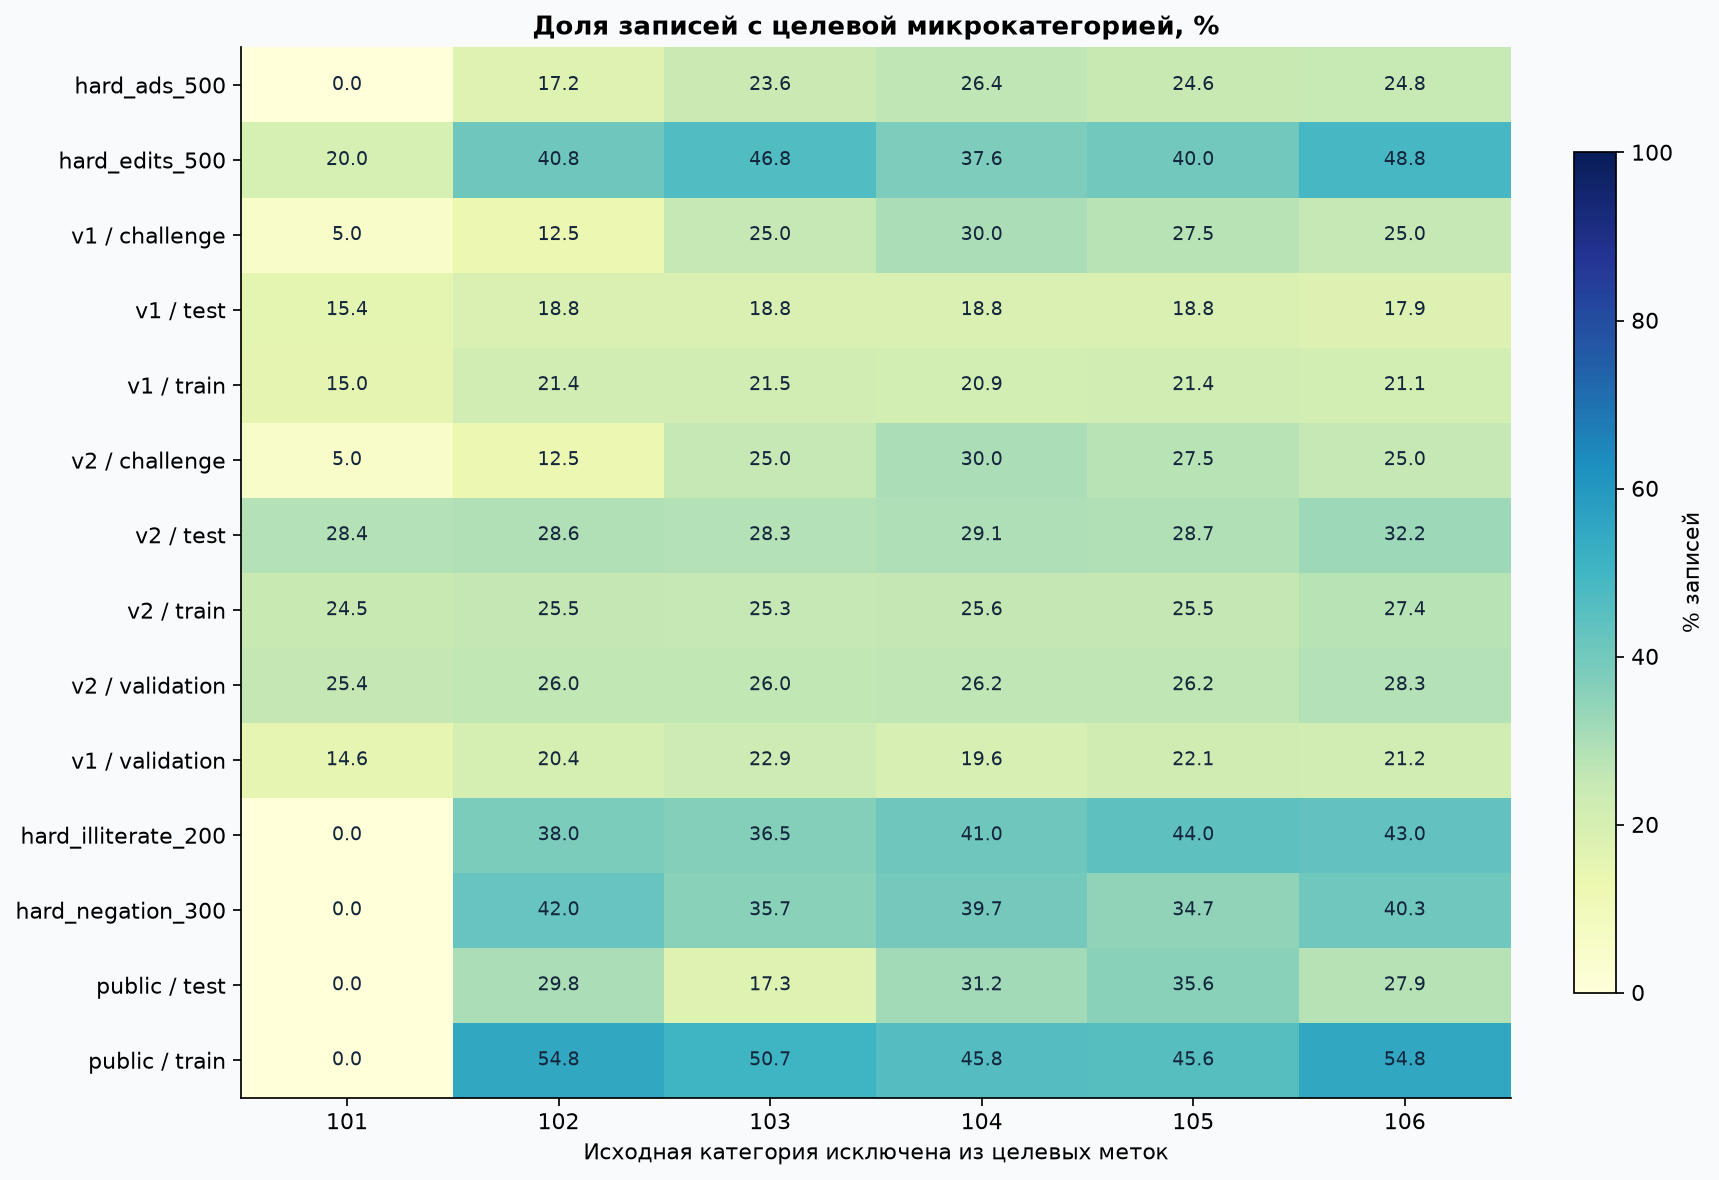

*Частоты целевых категорий по всем файлам. Частоты зависят также от распределения исходного mcId.*

In [6]:
show_chart("01_category_prevalence.png")

### Влияние повторов на распределение категорий

Частоты по строкам и по уникальным описаниям могут различаться: повторяющиеся
объявления получают больший вес. Прежде чем оставить один экземпляр текста,
проверяем отсутствие конфликтов внутри public train.

In [7]:
public_groups = {}
for row in data[eda.PUBLIC_TRAIN]:
    key = row["_key"]
    if key in public_groups:
        assert public_groups[key]["_labels"] == row["_labels"], "Конфликт меток: нужна проверка"
    public_groups[key] = row
unique_public = list(public_groups.values())
table(
    ["mcId", "По строкам, %", "По уникальным описаниям, %"],
    [[c, round(100 * public_train["label_counts"][str(c)] / public_train["rows"], 1),
      round(100 * sum(c in r["_labels"] for r in unique_public) / len(unique_public), 1)]
     for c in eda.IDS]
)
print("Размер самой большой группы повторов:", public_train["largest_duplicate_group"])

mcId,"По строкам, %","По уникальным описаниям, %"
101,0.0,0.0
102,54.8,51.3
103,50.7,48.6
104,45.8,47.8
105,45.6,47.4
106,54.8,54.7


Размер самой большой группы повторов: 94


### Число меток на объявление и их совместное появление

На диагонали матрицы — частота отдельной метки. В остальных ячейках — доля
всех строк v2 train, содержащих обе метки, а не условная вероятность.

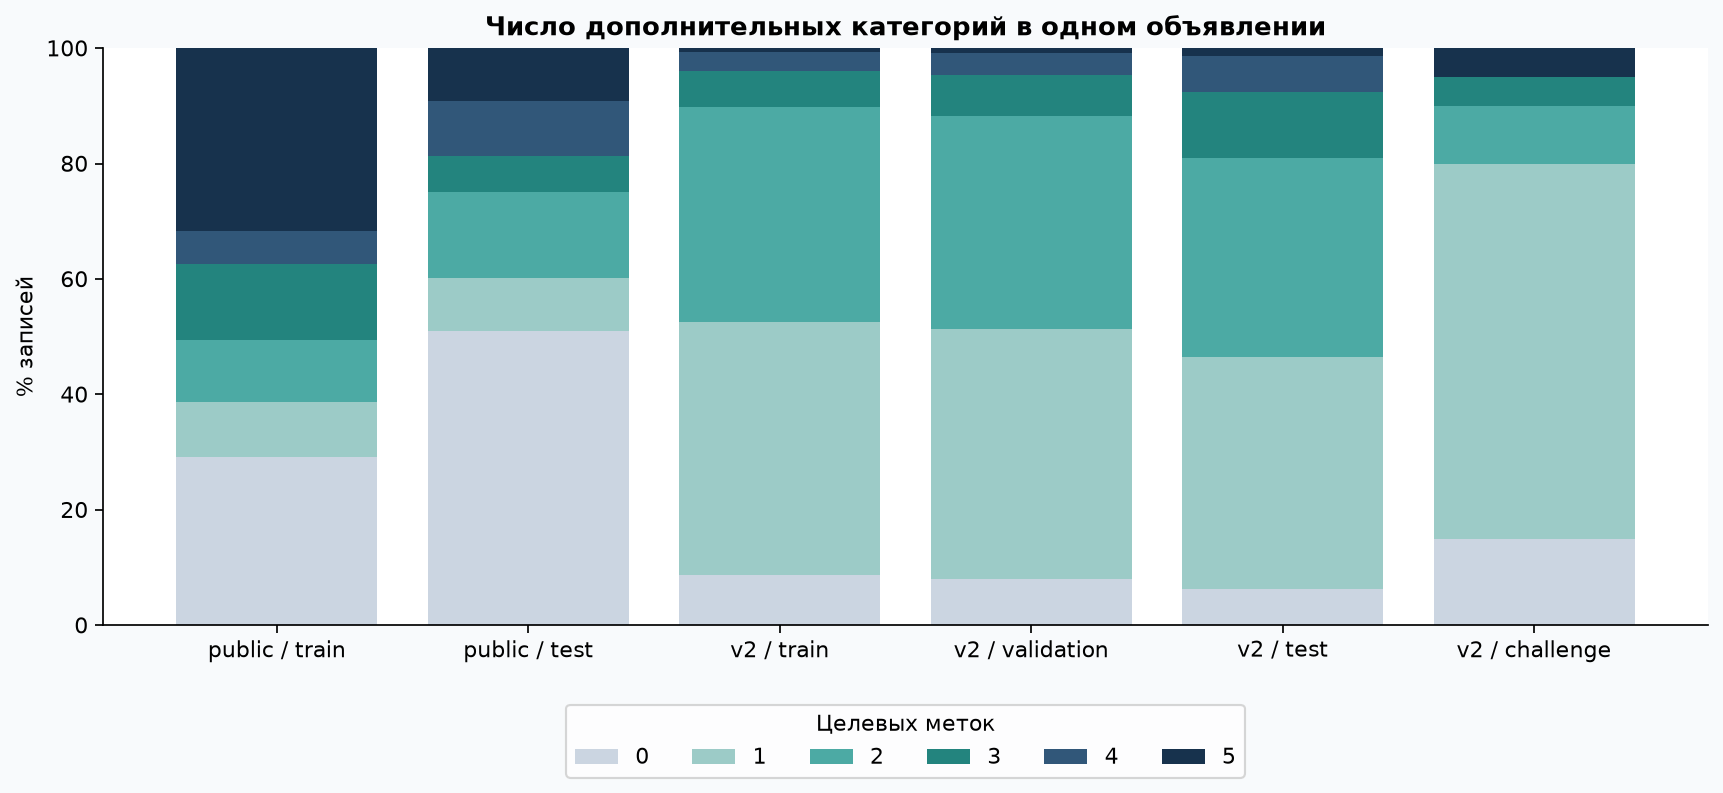

*Ноль означает отсутствие дополнительных черновиков, а не обязательно отсутствие предлагаемых услуг.*

In [8]:
show_chart("03_label_cardinality.png")

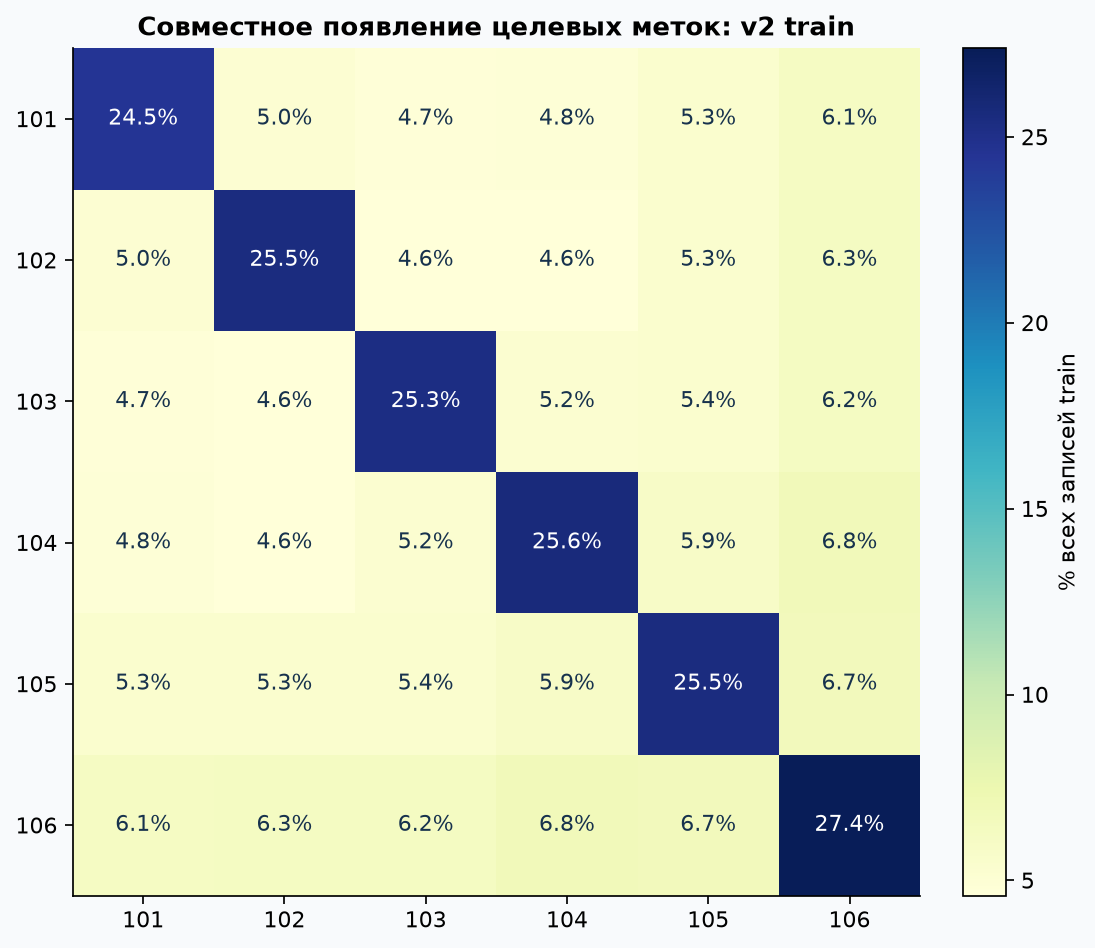

*Диагональ — частота отдельной метки; остальные ячейки — доля записей, содержащих обе метки.*

In [9]:
show_chart("06_label_cooccurrence.png")

## 4. Длины описаний

Длина измеряется в символах. «Слово» — последовательность латинских или
кириллических букв, а не токен LLM. На boxplot используется логарифмическая
шкала; скрытые на графике выбросы остаются в расчётах статистики.

Набор,Символов p50,p95,max,Слов p50,>6000 символов,>12000 символов
hard_ads_500,449.5,1558.1,1934.0,61.0,0,0
hard_edits_500,2077.0,4953.0,5434.0,263.5,0,0
v1 / challenge,101.0,123.2,151.0,14.0,0,0
v1 / test,140.0,269.0,290.0,20.0,0,0
v1 / train,127.0,166.0,203.0,18.0,0,0
v2 / challenge,101.0,123.2,151.0,14.0,0,0
v2 / test,155.0,415.0,433.0,21.0,0,0
v2 / train,143.0,409.0,530.0,19.0,0,0
v2 / validation,140.0,528.0,631.0,19.0,0,0
v1 / validation,133.5,172.1,193.0,19.0,0,0


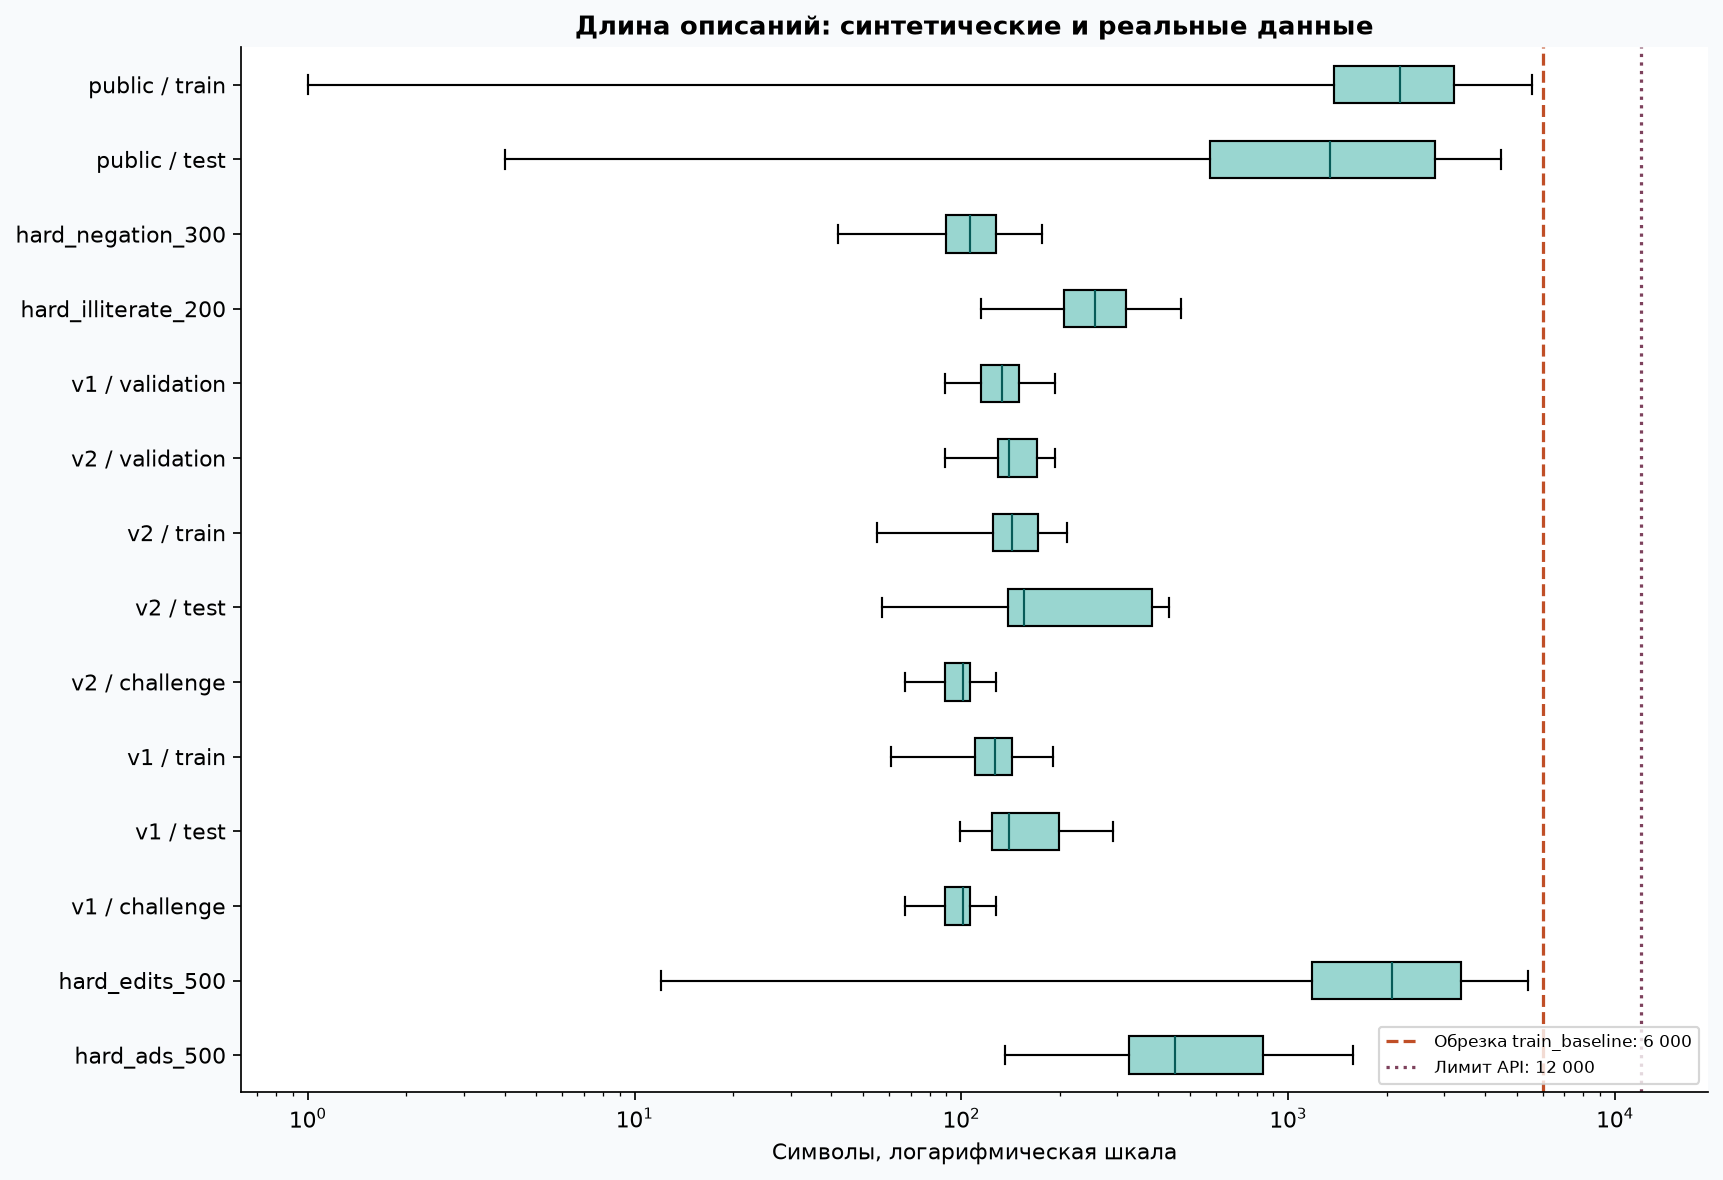

*Коробки показывают медиану и квартили; выбросы скрыты только на графике, статистика рассчитана по всем строкам.*

Описаний длиннее лимита обучения 6000: 0
Описаний длиннее лимита API 12000: 0


In [10]:
table(
    ["Набор", "Символов p50", "p95", "max", "Слов p50", ">6000 символов", ">12000 символов"],
    [[eda.short(name), s["characters"]["median"], s["characters"]["p95"],
      s["characters"]["max"], s["words"]["median"], s["over_6000_chars"], s["over_12000_chars"]]
     for name, s in stats.items()]
)
show_chart("02_text_lengths.png")
print("Описаний длиннее лимита обучения 6000:", sum(s["over_6000_chars"] for s in stats.values()))
print("Описаний длиннее лимита API 12000:", sum(s["over_12000_chars"] for s in stats.values()))

## 5. Отрицания и языковые ошибки

Количество отдельных слов НЕ/НИ/НЕТ — лексический показатель, не глубина
отрицания. Например, «неделаю» не попадёт в этот счётчик. Смешение кириллицы
и латиницы может быть обфускацией, артикулом или названием; оно не доказывает
грамматическую ошибку. Глубина и тип искажений взяты из аннотаций синтетики.
«Не размечено» не означает отсутствие отрицаний или ошибок.

Набор,"НЕ/НИ/НЕТ, %","≥2 таких слов, %","ТОЛЬКО/ЛИШЬ/ИСКЛЮЧИТЕЛЬНО, %","Смешение алфавитов, %"
hard_ads_500,47.8,34.2,16.2,0.0
hard_edits_500,67.6,45.6,26.4,24.6
v1 / challenge,87.5,37.5,47.5,0.0
v1 / test,100.0,62.5,25.0,0.0
v1 / train,75.0,20.5,25.0,0.0
v2 / challenge,87.5,37.5,47.5,0.0
v2 / test,99.7,69.8,2.0,0.0
v2 / train,95.8,45.1,10.3,0.0
v2 / validation,86.1,44.4,2.5,0.0
v1 / validation,75.0,12.5,25.0,0.0


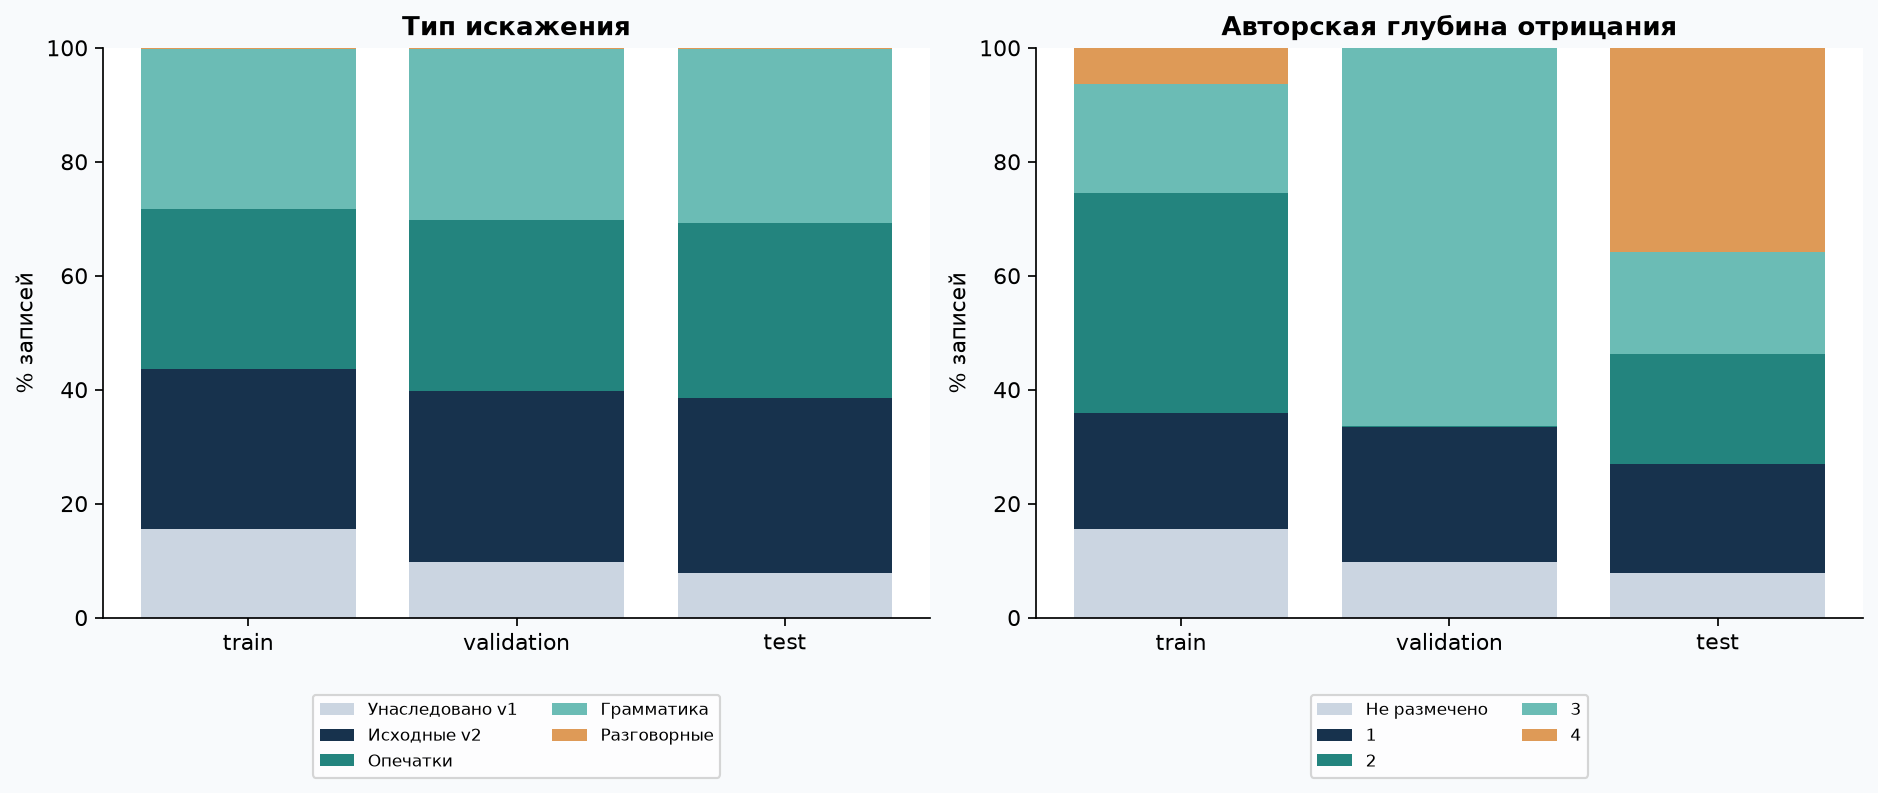

*Глубина — аннотация сценария, не подсчёт НЕ. Не размечено не означает отсутствие отрицаний.*

In [11]:
marker_fields = ["standalone_negation_rows", "two_or_more_negation_tokens_rows",
                 "only_marker_rows", "mixed_script_word_rows"]
table(
    ["Набор", "НЕ/НИ/НЕТ, %", "≥2 таких слов, %", "ТОЛЬКО/ЛИШЬ/ИСКЛЮЧИТЕЛЬНО, %", "Смешение алфавитов, %"],
    [[eda.short(name), *[round(100 * s[key] / s["rows"], 1) for key in marker_fields]]
     for name, s in stats.items()]
)
show_chart("05_v2_coverage.png")

## 6. Дубликаты и пересечения выборок

Нормализация: `casefold` и свёртка пробелов. Пунктуация, частицы и опечатки
сохраняются. Заголовок не учитывается, поскольку сервис получает описание.
Разные заголовки могут объяснять часть исходной разметки, но для модели,
которая получает только описание, неоднозначность сохраняется.

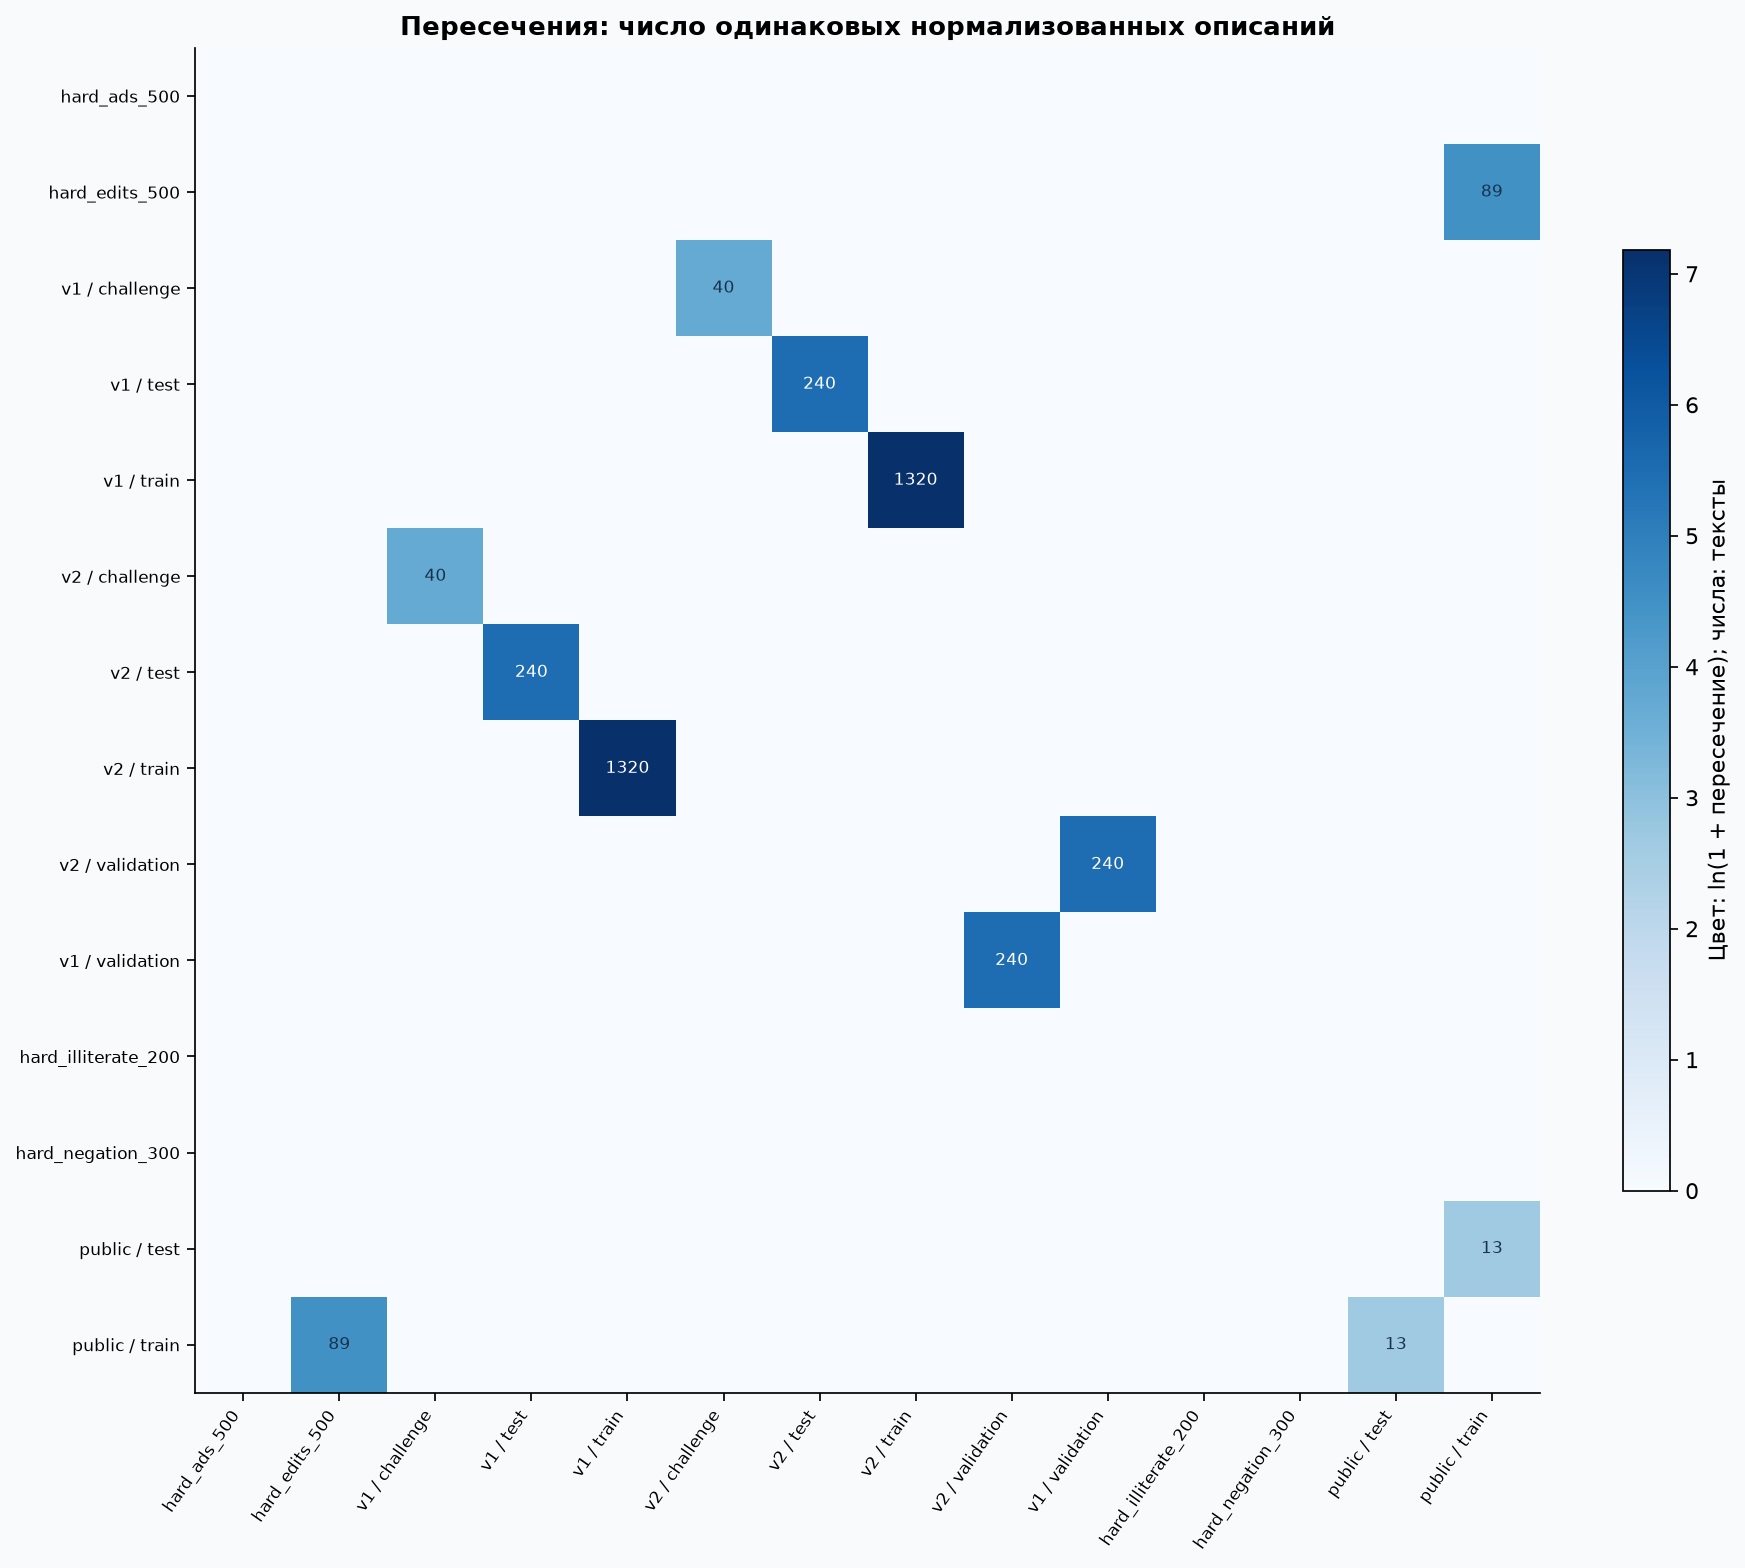

*Диагональ скрыта. Повтор v1 внутри v2 ожидаем; пересечение public train/test влияет на независимость оценки.*

Файл A,Файл B,Общих уникальных текстов,Строк A,Строк B
distillate_dataset/hard_edits_500.jsonl,public/public-train-annotated.jsonl,89,100,1036
hard_dataset/challenge.jsonl,hard_dataset/v2/challenge.jsonl,40,40,40
hard_dataset/test.jsonl,hard_dataset/v2/test.jsonl,240,240,240
hard_dataset/train.jsonl,hard_dataset/v2/train.jsonl,1320,1320,1320
hard_dataset/v2/validation.jsonl,hard_dataset/validation.jsonl,240,240,240
public/public-test-dataset.parquet,public/public-train-annotated.jsonl,13,24,168


In [12]:
show_chart("04_text_overlap.png")
table(
    ["Файл A", "Файл B", "Общих уникальных текстов", "Строк A", "Строк B"],
    [[p["a"], p["b"], p["unique_texts"], p["rows_a"], p["rows_b"]]
     for p in overlap["overlaps"]]
)

### Конфликтующие метки

Ниже — адреса всех строк конфликтных групп. Одинаковое описание считается
конфликтующим, только если при одинаковом исходном `mcId` есть разные наборы
целей. Автоматически выбирать разметку большинством здесь нельзя.

In [13]:
conflicts = overlap["conflicting_text_groups"]
print("Групп конфликтующих описаний:", len(conflicts))
conflict_rows = []
for group_no, group in enumerate(conflicts, 1):
    for entry in group["occurrences"]:
        conflict_rows.append([group_no, entry["file"], entry["line"], entry["item_id"],
                              entry["source"], ", ".join(map(str, entry["labels"])) or "∅"])
table(["Группа", "Файл", "Строка", "item_id", "Источник", "Целевые категории"], conflict_rows)

Групп конфликтующих описаний: 13


Группа,Файл,Строка,item_id,Источник,Целевые категории
1,public/public-test-dataset.parquet,1,parquet-row-1,101,"102, 103, 105, 106"
1,public/public-test-dataset.parquet,29,parquet-row-29,101,∅
1,public/public-test-dataset.parquet,55,parquet-row-55,101,"103, 104, 105, 106"
1,public/public-test-dataset.parquet,71,parquet-row-71,101,"102, 103, 104, 105, 106"
1,public/public-test-dataset.parquet,136,parquet-row-136,101,"102, 103, 104, 105, 106"
1,public/public-test-dataset.parquet,168,parquet-row-168,101,"103, 104, 105, 106"
1,public/public-test-dataset.parquet,208,parquet-row-208,101,"102, 103, 104, 105, 106"
2,public/public-test-dataset.parquet,14,parquet-row-14,101,"103, 104, 105"
2,public/public-test-dataset.parquet,59,parquet-row-59,101,∅
3,public/public-test-dataset.parquet,16,parquet-row-16,101,"102, 104, 105, 106"


### Проверка разбиения и происхождения

Контролируемые правки должны оставаться в одной выборке со своими исходниками
по `source_item_id`. Для v2 отдельно проверяем тексты, смысловые группы и
семейства формулировок. Отсутствие точных совпадений не доказывает полной
семантической независимости: общая лексика и логические операции сохраняются.

In [14]:
assert not overlap["v2_group_leaks"], "Смысловые группы пересекают выборки"
assert not overlap["v2_family_leaks"], "Семейства шаблонов пересекают выборки"
assert not any(p["a"].startswith(eda.V2) and p["b"].startswith(eda.V2)
               for p in overlap["overlaps"]), "Тексты пересекают выборки v2"
edits = data["distillate_dataset/hard_edits_500.jsonl"]
print("v2: пересечений текстов, групп и семейств между выборками нет.")
print("Контролируемых правок:", len(edits),
      "| Исходных объявлений:", len({r["source_item_id"] for r in edits}))
table(["Входной файл", "SHA-256"], [[r["path"], r["sha256"]] for r in inventory])

v2: пересечений текстов, групп и семейств между выборками нет.
Контролируемых правок: 500 | Исходных объявлений: 500


Входной файл,SHA-256
public/public-test-dataset.parquet,65b5a45a98b577d853a928932bbbdf8bd9bdeb469ded3016faace4d11f3eabaa
public/public-train-annotated.jsonl,b7118d68086624fbeab43839f22a635d4e325e4ee339f22d4aa0ad3c2e986615
distillate_dataset/hard_ads_500.jsonl,bb45e59842c1bee97aafc5680e939c41df09fa85a890e32edb5e16594899c07f
distillate_dataset/hard_edits_500.jsonl,5d56d53417fd70423117faf9fde2ba770291c50f20124890e89ba7cde8f094ea
hard_dataset/challenge.jsonl,db175819218e54da469e270feb8c8815fee2c9942b50ab85349142e45e2e5590
hard_dataset/test.jsonl,6df1dce2276fa037d2bafbaf629a09697efe5c8df4681328a60ade8815f78dc5
hard_dataset/train.jsonl,d9ab439cd8bb68dddb9b9c846d42b8f6a5f5aaf88edc183f9167d93e5ab4c221
hard_dataset/v2/challenge.jsonl,db175819218e54da469e270feb8c8815fee2c9942b50ab85349142e45e2e5590
hard_dataset/v2/test.jsonl,cde5099d8177e12bd4054548e17e6fd2c60af0740823614e669b331e6c3a7c55
hard_dataset/v2/train.jsonl,0d5bcb4de37cbe2e0efaa990ef8af13bef25239437b03c4559d88edeea0839e9


## 7. Выводы по текущим данным

In [15]:
common = next(p for p in overlap["overlaps"]
              if {p["a"], p["b"]} == {eda.PUBLIC_TRAIN, eda.PUBLIC_TEST})
train_matches = common["rows_a"] if common["a"] == eda.PUBLIC_TRAIN else common["rows_b"]
test_matches = common["rows_a"] if common["a"] == eda.PUBLIC_TEST else common["rows_b"]
display(Markdown(
    f"- Public train: **{public_train['unique_texts']:,} уникальных описаний** "
    f"из {public_train['rows']:,} строк; "
    f"{100 * public_train['duplicate_extra_rows'] / public_train['rows']:.1f}% — повторы сверх первого.\n"
    f"- Public train/test: **{common['unique_texts']} общих описаний**, "
    f"{train_matches} строк train и {test_matches} строк test.\n"
    f"- Найдено **{len(conflicts)} конфликтных групп**.\n"
    f"- V2 train: медианная длина **{v2_train['characters']['median']:g} символа**, "
    f"public train — **{public_train['characters']['median']:g}**.\n"
    f"- Пустые ответы в v2 train: **{100 * v2_train['empty_targets'] / v2_train['rows']:.1f}%**.\n"
    "- Внутри v2 пересечений текстов, групп и семейств между выборками нет."
))

- Public train: **4,855 уникальных описаний** из 10,000 строк; 51.5% — повторы сверх первого.
- Public train/test: **13 общих описаний**, 168 строк train и 24 строк test.
- Найдено **13 конфликтных групп**.
- V2 train: медианная длина **143 символа**, public train — **2196**.
- Пустые ответы в v2 train: **8.7%**.
- Внутри v2 пересечений текстов, групп и семейств между выборками нет.

## 8. Рекомендации и ограничения

- Использовать готовые train/validation/test v2; **не добавлять v1 повторно**.
  Реальные объявления разделять после дедупликации, вместе с их производными.
- Публичный тест оставить вне обучения. Для оценки обобщения нужна независимая
  проверенная реальная выборка без конфликтов и пересечений с обучением.
- Подбирать долю синтетики на реальной валидации. Короткие формальные фразы
  не заменяют длинные реальные объявления.
- Для модели только по описанию обучать на `offered_microcategories`, затем
  исключать исходный `mcId`. Для модели с описанием и `mcId` допустимы цели
  `found_microcategories`. Текущий baseline поддерживает только 102–106;
  для шести категорий требуется добавить 101.
- Не передавать модели поля `note`, `type`, `group_id`, `variant`,
  `augmentation`, `negation_depth` и метки в качестве входных признаков.
- Измерять micro-F1, F1 по категориям, точное совпадение, ложные положительные
  на пустых ответах, полностью правильные контрастные пары и устойчивость
  к искажённым версиям. Пороги выбирать на validation, не на test.

Модель в этом notebook не обучается. EDA не доказывает качество каждой метки
и не заменяет ручную разметку. Смысловая глубина — аннотация сценария;
автоматического надёжного подсчёта всех грамматических ошибок здесь нет.
Подробный исторический аудит: `datasets/hard_dataset/AUDIT.md`.